
# Experiment 8: Classification Model – Handwritten Digit Recognition

## Aim
To build, train, evaluate, and compare a Logistic Regression model
and a Dense Neural Network for recognizing handwritten digits
from 0 to 9 using the MNIST dataset.

## Objectives
- Load and explore the MNIST dataset.
- Normalize pixel values and flatten images.
- Train a Logistic Regression baseline model.
- Build and train a Dense Neural Network.
- Evaluate both models using accuracy, precision, recall, F1-score,
  and a confusion matrix.
- Compare model performance and interpret the results.

## Dataset Description
The MNIST dataset contains 70,000 grayscale images of handwritten
digits. Each image has dimensions of 28 × 28 pixels.

- Training samples: 60,000
- Testing samples: 10,000
- Input image size: 28 × 28 pixels
- Number of classes: 10 (digits 0–9)
- Pixel intensity range: 0–255

## Tools and Libraries
Python, NumPy, Matplotlib, Seaborn, Scikit-learn,
TensorFlow/Keras, and Jupyter Notebook.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print("Pixel range:", X_train.min(), X_train.max())


(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
Pixel range: 0 255



## 2. Visualize Sample Images

Ten sample images are displayed with their corresponding labels.
This helps us understand the appearance of handwritten digits
and identify similarities between different classes.


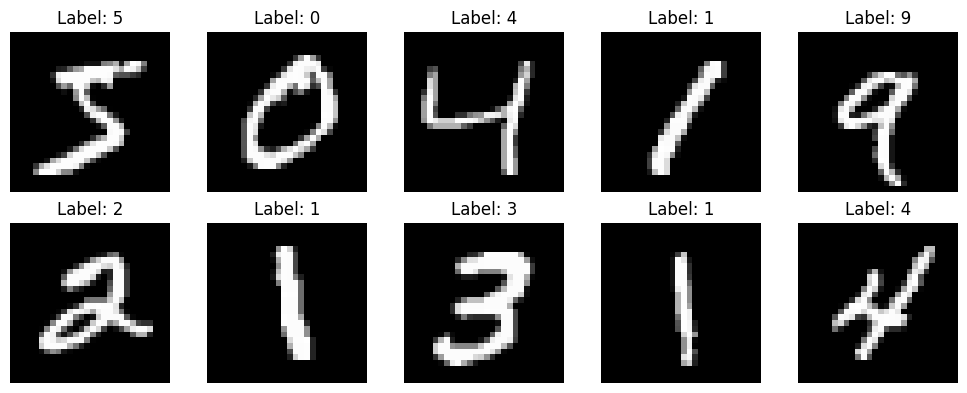

In [4]:

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()



### Observation

The dataset contains handwritten digits with different shapes,
sizes, and stroke patterns. Digits with distinct shapes are
easier to recognize, while visually similar digits may be
misclassified.



## 3. Data Preprocessing

Pixel values are normalized by dividing them by 255, converting
the range from 0–255 to 0–1.

Each 28 × 28 image is then flattened into a one-dimensional
vector containing 784 features. Flattening changes the shape
of each image but does not change the number of samples.


In [5]:

# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten images into 784 features
X_train_flat = X_train.reshape(-1, 784)
X_test_flat = X_test.reshape(-1, 784)

print("Flattened training shape:", X_train_flat.shape)
print("Flattened testing shape:", X_test_flat.shape)


Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)



## 4. Model A: Baseline Logistic Regression

Logistic Regression is used as the baseline classification model.
It learns the relationship between the 784 pixel features and
the ten possible digit classes.

The model is trained using the training dataset and evaluated
on the test dataset using classification metrics.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_lr = LogisticRegression(
    max_iter=100,
    solver="lbfgs"
)

model_lr.fit(X_train_flat, y_train)

y_pred_lr = model_lr.predict(X_test_flat)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, digits=4))


C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Accuracy: 0.9253

Classification Report:
              precision    recall  f1-score   support

           0     0.9504    0.9776    0.9638       980
           1     0.9644    0.9789    0.9716      1135
           2     0.9281    0.9002    0.9139      1032
           3     0.9020    0.9109    0.9064      1010
           4     0.9365    0.9308    0.9336       982
           5     0.9029    0.8756    0.8890       892
           6     0.9343    0.9499    0.9420       958
           7     0.9368    0.9232    0.9299      1028
           8     0.8770    0.8789    0.8779       974
           9     0.9113    0.9167    0.9140      1009

    accuracy                         0.9253     10000
   macro avg     0.9244    0.9242    0.9242     10000
weighted avg     0.9252    0.9253    0.9252     10000




## 5. Confusion Matrix Analysis

A confusion matrix compares the actual labels with the predicted
labels. The diagonal represents correct predictions, while
off-diagonal entries represent misclassifications.

For digit 5, the problem can be treated as binary classification
using a one-vs-rest approach:

- True Positive (TP): Actual 5 predicted as 5.
- False Positive (FP): Other digits predicted as 5.
- False Negative (FN): Actual 5 predicted as another digit.
- True Negative (TN): Other digits correctly predicted as not 5.


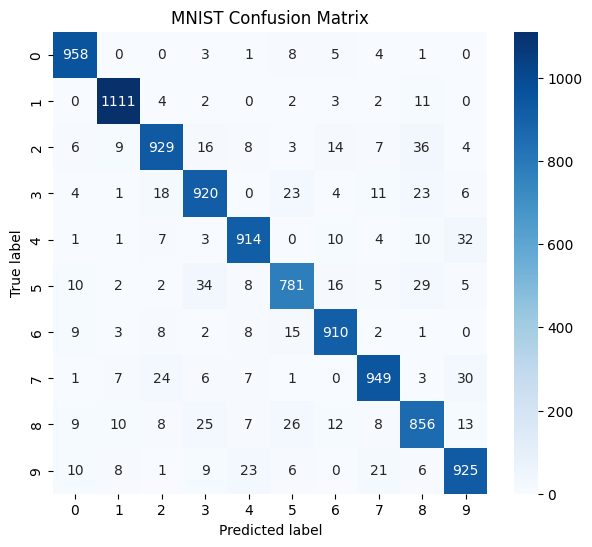

In [8]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("MNIST Confusion Matrix")
plt.show()


### Interpretation

The diagonal values indicate correctly classified images.
The largest diagonal value identifies the digit with the most
correct predictions.

The largest off-diagonal value identifies the most frequent
directed confusion between two digits.

Accuracy alone is insufficient because it does not show the
individual performance of each class. Precision, recall,
F1-score, and the confusion matrix provide a more complete
evaluation of the model.



## 7. Evaluate the Neural Network

The trained neural network is evaluated using the test dataset.
The output layer produces ten class probabilities through Softmax.
The predicted digit is selected using the highest probability.

The classification report provides precision, recall, F1-score,
and support for each digit class.


In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
model_nn = Sequential([
    Dense(128, activation="relu", input_shape=(784,)),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])
model_nn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
    )
history = model_nn.fit(
    X_train_flat,
    y_train, 
    validation_split=0.1, 
    epochs=10, 
    batch_size=128, 
    verbose=1
    )

test_loss, test_acc = model_nn.evaluate(X_test_flat, y_test, verbose=0)

probabilities = model_nn.predict(X_test_flat)

y_pred_nn = np.argmax(probabilities, axis=1)

print("Test accuracy:", test_acc)
print(classification_report(y_test, y_pred_nn))


C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8818 - loss: 0.4043 - val_accuracy: 0.9608 - val_loss: 0.1477
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9484 - loss: 0.1735 - val_accuracy: 0.9682 - val_loss: 0.1043
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9606 - loss: 0.1296 - val_accuracy: 0.9760 - val_loss: 0.0831
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9680 - loss: 0.1042 - val_accuracy: 0.9772 - val_loss: 0.0790
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9732 - loss: 0.0895 - val_accuracy: 0.9755 - val_loss: 0.0789
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9759 - loss: 0.0774 - val_accuracy: 0.9797 - val_loss: 0.0685
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9785 - loss: 0.0677 - val_accuracy: 0.9775 - val_loss: 0.0782
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9811 - loss: 0.0611 - val_accuracy: 0.


## 8. Training and Validation Accuracy

Training accuracy measures the performance on training data.
Validation accuracy measures the performance on the validation
subset that is not used for weight updates.

A large difference between training and validation accuracy
may indicate overfitting. Increasing accuracy across both
curves generally indicates that the model is learning.


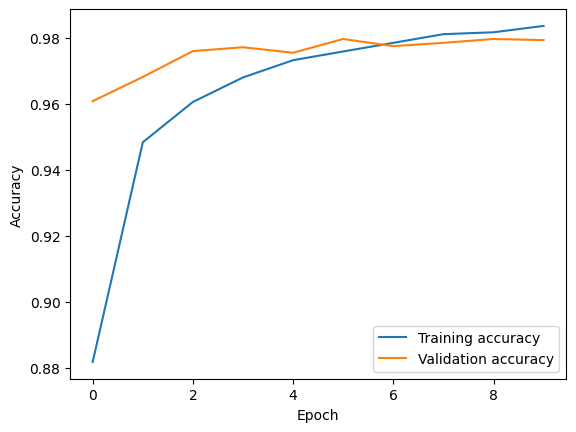

In [10]:
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()



### Result Interpretation

The model with higher test accuracy and stronger macro
precision, recall, and F1-score has better overall performance.

The Dense Neural Network is expected to perform better because
it can learn nonlinear patterns and complex combinations of
pixels. The final conclusion should be based on the actual
metrics printed during execution.

## 10. Result

The MNIST handwritten digit recognition experiment was
implemented using Logistic Regression and a Dense Neural
Network. Both models were trained and evaluated on the test
dataset. Their performance was compared using accuracy,
macro precision, macro recall, macro F1-score, and a
confusion matrix.

## 11. Conclusion

The experiment demonstrates the application of multiclass
classification to handwritten digit recognition. Data
normalization, flattening, model training, and evaluation
were performed. Comparing the baseline model with the neural
network illustrates how nonlinear learning can improve
classification performance.

## 12. Viva Questions and Answers

**Q1. Why is MNIST a multiclass classification problem?**

MNIST has ten possible target classes, representing digits 0 to 9.

**Q2. What is the difference between features and target?**

Features are the pixel values of an image. The target is the
actual digit label.

**Q3. Why are pixel values normalized?**

Normalization scales pixel values between 0 and 1, helping
neural networks train more effectively.

**Q4. Why is Softmax used in the output layer?**

Softmax converts output scores into probabilities for the
ten classes, summing to 1.

**Q5. What does a diagonal value in a confusion matrix represent?**

It represents the number of correctly classified samples
for the corresponding class.

**Q6. What is macro average?**

Macro average calculates a metric independently for every class
and takes the unweighted mean of the ten values.

**Q7. What is Dropout?**

Dropout randomly disables a fraction of neurons during training
to help reduce overfitting.

**Q8. Why is Adam used?**

Adam is an adaptive optimization algorithm that adjusts
parameter updates using estimates of gradients and their moments.

**Q9. What is the difference between accuracy and F1-score?**

Accuracy measures the proportion of correct predictions.
F1-score is the harmonic mean of precision and recall.

**Q10. Why can high accuracy hide weak class performance?**

A model may perform poorly on individual classes despite
high overall accuracy. Per-class metrics reveal these weaknesses.


